# Algorithm Repetition & Starvation Analysis Pipeline


In [1]:
# ======================================================
# Cell 1: Install Dependencies
# ======================================================
import subprocess, sys

for _pkg in ["numpy", "pandas", "matplotlib", "seaborn", "openpyxl"]:
    subprocess.check_call([sys.executable, "-m", "pip", "install", _pkg, "-q"])

print("✅ All dependencies installed.")


✅ All dependencies installed.


In [2]:
# ======================================================
# Cell 2: Platform Detection & Path Configuration
# ======================================================
import os, sys

IS_COLAB = "google.colab" in sys.modules

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    ROOT_DIR = "/content/drive/MyDrive"
    print("✅ Running on Google Colab — Google Drive mounted.")
else:
    ROOT_DIR = os.path.dirname(os.getcwd())
    print(f"✅ Running locally — root: {ROOT_DIR}")

RESULTS_DIR = os.path.join(ROOT_DIR, "RESULTS")
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f"📁 Results folder: {RESULTS_DIR}")

def pick_file(title="Select a file", filetypes=(("CSV/Excel files", "*.csv *.xlsx"),)):
    """
    Returns a local file path string.
    • Colab : uses google.colab.files.upload() and writes bytes to /tmp.
    • Local : prompts you to paste/type the full file path.
    """
    if IS_COLAB:
        from google.colab import files as _colab_files
        uploaded = _colab_files.upload()
        if not uploaded:
            raise RuntimeError("No file uploaded.")
        fname = next(iter(uploaded))
        path  = f"/tmp/{fname}"
        with open(path, "wb") as fh:
            fh.write(uploaded[fname])
        return path
    else:
        print(f"\n📂 {title}")
        print("   Paste the full path to your file and press Enter.")
        print("   Example: /Users/you/project/Data/dataset.xlsx")
        path = input("   Path: ").strip().strip('"').strip("'")
        if not path:
            raise RuntimeError("No path entered.")
        if not os.path.exists(path):
            raise FileNotFoundError(
                f"File not found at:\n  {path}\n"
                "Check the path and re-run this cell."
            )
        return path

print("✅ Platform setup complete.")


✅ Running locally — root: /Users/aumgarasia/Desktop/SPE_2026
📁 Results folder: /Users/aumgarasia/Desktop/SPE_2026/RESULTS
✅ Platform setup complete.


In [3]:
# ======================================================
# Cell 3: Load Dataset
# ======================================================
import numpy as np
import pandas as pd
import io

RTW_FRACTIONS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

print("Select your CSV or Excel dataset file.")
data_path = pick_file(title="Select dataset (.csv or .xlsx)")
print(f"Loading: {data_path}")

if data_path.lower().endswith((".xlsx", ".xls")):
    df_input = pd.read_excel(data_path)
else:
    df_input = pd.read_csv(data_path, encoding="utf-8", errors="replace")

print(f"✅ Loaded: {df_input.shape[0]} rows × {df_input.shape[1]} columns")
print(f"   Columns: {df_input.columns.tolist()}")


Select your CSV or Excel dataset file.

📂 Select dataset (.csv or .xlsx)
   Paste the full path to your file and press Enter.
   Example: /Users/you/project/Data/dataset.xlsx


   Path:  /Users/aumgarasia/Desktop/SPE_2026/Sensitivity Analysis/Task 3/D1-BV.xlsx


Loading: /Users/aumgarasia/Desktop/SPE_2026/Sensitivity Analysis/Task 3/D1-BV.xlsx
✅ Loaded: 488 rows × 4 columns
   Columns: ['tc_id', 'us_id', 'tc_executiontime', 'us_businessvalue']


In [4]:
# ======================================================
# Cell 4: Build Model & Algorithm Definitions
# ======================================================
import numpy as np

def build_model(df):
    t_ids = np.sort(df["tc_id"].unique())
    r_ids = np.sort(df["us_id"].unique())
    t_idx = {id: i for i, id in enumerate(t_ids)}
    r_idx = {id: i for i, id in enumerate(r_ids)}
    t_et  = np.array([float(df[df["tc_id"]==id]["tc_executiontime"].iloc[0]) for id in t_ids])
    r_bv  = np.array([float(df[df["us_id"]==id]["us_businessvalue"].iloc[0]) for id in r_ids])

    t_to_r = [np.array([r_idx[u] for u in df[df["tc_id"]==id]["us_id"]]) for id in t_ids]
    r_tc   = np.array([len(df[df["us_id"]==id]) for id in r_ids])

    r_to_t = [[] for _ in range(len(r_ids))]
    for _, row in df.iterrows():
        r_to_t[r_idx[row["us_id"]]].append(t_idx[row["tc_id"]])
    r_to_t = [np.array(tlist) for tlist in r_to_t]

    return {
        "t_ids": t_ids, "r_ids": r_ids,
        "t_et":  t_et,  "r_bv":  r_bv,
        "t_to_r": t_to_r, "r_tc": r_tc, "r_to_t": r_to_t,
        "n_t": len(t_ids), "n_r": len(r_ids),
    }


def run_algo_greedy(m, budget, w=None, defs=None):
    sel_t, u_et = np.zeros(m["n_t"], dtype=bool), 0.0
    r_cnt, r_sat = np.zeros(m["n_r"], dtype=int), np.zeros(m["n_r"], dtype=bool)
    while True:
        best_t, best_s, fair = -1, 0.0, False
        cands = []
        for ti in range(m["n_t"]):
            if sel_t[ti] or (u_et + m["t_et"][ti] > budget): continue
            fb, bg = 0.0, 0.0
            for rj in m["t_to_r"][ti]:
                if not r_sat[rj] and (r_cnt[rj]+1 == m["r_tc"][rj]):
                    bg += m["r_bv"][rj] * (w[rj] if w is not None else 1.0)
                    if defs is not None and defs[rj] > 0: fb += defs[rj]
            cands.append((ti, fb, bg)); fair = fair or (fb > 0)
        for ti, fb, bg in cands:
            score = (fb if fair else bg) / m["t_et"][ti]
            if score > best_s: best_s, best_t = score, ti
        if best_t == -1: break
        sel_t[best_t], u_et = True, u_et + m["t_et"][best_t]
        for rj in m["t_to_r"][best_t]:
            if not r_sat[rj]:
                r_cnt[rj] += 1
                if r_cnt[rj] == m["r_tc"][rj]: r_sat[rj] = True
    return {"sat": r_sat, "tests": sel_t,
            "bv": m["r_bv"][r_sat].sum(), "cvg": 100.0 * sel_t.sum() / m["n_t"]}


def run_algo_round_robin(m, budget, order, start_head):
    sel_t, u_et = np.zeros(m["n_t"], dtype=bool), 0.0
    r_sat = np.zeros(m["n_r"], dtype=bool)
    L, head, added = len(order), start_head % len(order), True
    while added and u_et < budget:
        added = False
        for offset in range(L):
            rj       = order[(head + offset) % L]
            if r_sat[rj]: continue
            t_indices = m["r_to_t"][rj]
            extra_et  = sum(m["t_et"][ti] for ti in t_indices if not sel_t[ti])
            if extra_et == 0:
                r_sat[rj] = True; added = True; continue
            if u_et + extra_et <= budget:
                for ti in t_indices: sel_t[ti] = True
                u_et += extra_et; r_sat[rj] = True; added = True
        head = (head + 1) % L
    return {"sat": r_sat, "tests": sel_t,
            "bv": m["r_bv"][r_sat].sum(), "cvg": 100.0 * sel_t.sum() / m["n_t"],
            "last_head": head}


print("✅ Model and algorithm functions defined.")


✅ Model and algorithm functions defined.


In [5]:
# ======================================================
# Cell 5: Run Experiment
# ======================================================

m     = build_model(df_input)
algos = ["MemLess", "Aging", "DRR", "RR", "WRR"]
perf, stab = [], []
hm_r,  hm_t  = {a: [] for a in algos}, {a: [] for a in algos}
sel_mat_r, sel_mat_t = {a: [] for a in algos}, {a: [] for a in algos}

r_wait  = {a: np.zeros(m["n_r"]) for a in algos}
t_wait  = {a: np.zeros(m["n_t"]) for a in algos}
age     = np.ones(m["n_r"])
s_cnt   = np.zeros(m["n_r"])
p_sets  = {a: set() for a in algos}

rr_head, wrr_head = 0, 0
rr_order  = np.arange(m["n_r"])
avg_bv    = m["r_bv"].mean() if m["r_bv"].sum() > 0 else 1.0
wrr_weights = np.clip(np.round(m["r_bv"] / avg_bv), 1, 5).astype(int)
wrr_order   = np.array([idx for idx, w in enumerate(wrr_weights) for _ in range(w)])

print(f"Running {len(algos)} algorithms × {len(RTW_FRACTIONS)} RTW fractions...")

for k, frac in enumerate(RTW_FRACTIONS, 1):
    budget = frac * m["t_et"].sum()
    for a in algos:
        if   a == "MemLess": res = run_algo_greedy(m, budget)
        elif a == "Aging":   res = run_algo_greedy(m, budget, w=age)
        elif a == "DRR":     res = run_algo_greedy(m, budget,
                                 defs=((k * m["r_bv"] / m["r_bv"].sum()) - s_cnt))
        elif a == "RR":
            res = run_algo_round_robin(m, budget, rr_order, rr_head)
            rr_head = res["last_head"]
        elif a == "WRR":
            res = run_algo_round_robin(m, budget, wrr_order, wrr_head)
            wrr_head = res["last_head"]

        perf.append({"Algorithm": a, "RTW Fraction": frac,
                     "BV": res["bv"], "Coverage": res["cvg"]})

        for j in range(m["n_r"]):
            hm_r[a].append({"RTW Fraction": frac, "Req_ID": m["r_ids"][j], "Wait": r_wait[a][j]})
            sel_mat_r[a].append({"RTW Fraction": frac, "Req_ID": m["r_ids"][j], "Selected": int(res["sat"][j])})
        for j in range(m["n_t"]):
            hm_t[a].append({"RTW Fraction": frac, "Test_ID": m["t_ids"][j], "Wait": t_wait[a][j]})
            sel_mat_t[a].append({"RTW Fraction": frac, "Test_ID": m["t_ids"][j], "Selected": int(res["tests"][j])})

        curr = set(m["r_ids"][res["sat"]])
        if k > 1:
            stab.append({"Algorithm": a, "RTW Fraction": frac,
                         "Overlap_Pct": (len(p_sets[a] & curr) / len(p_sets[a]) * 100)
                         if p_sets[a] else 0})

        r_wait[a] += 1; r_wait[a][res["sat"]]   = 0
        t_wait[a] += 1; t_wait[a][res["tests"]] = 0
        if a == "Aging": age += 1.0; age[res["sat"]] = 0.0
        if a == "DRR":   s_cnt += res["sat"].astype(float)
        p_sets[a] = curr

print("✅ Experiment complete.")


Running 5 algorithms × 8 RTW fractions...
✅ Experiment complete.


In [15]:
print([d for d in perf if d['Algorithm'] == 'MemLess'])

[{'Algorithm': 'MemLess', 'RTW Fraction': 0.1, 'BV': np.float64(100.0), 'Coverage': np.float64(25.0)}, {'Algorithm': 'MemLess', 'RTW Fraction': 0.2, 'BV': np.float64(244.0), 'Coverage': np.float64(30.0)}, {'Algorithm': 'MemLess', 'RTW Fraction': 0.3, 'BV': np.float64(244.0), 'Coverage': np.float64(30.0)}, {'Algorithm': 'MemLess', 'RTW Fraction': 0.4, 'BV': np.float64(244.0), 'Coverage': np.float64(30.0)}, {'Algorithm': 'MemLess', 'RTW Fraction': 0.5, 'BV': np.float64(244.0), 'Coverage': np.float64(30.0)}, {'Algorithm': 'MemLess', 'RTW Fraction': 0.6, 'BV': np.float64(244.0), 'Coverage': np.float64(30.0)}, {'Algorithm': 'MemLess', 'RTW Fraction': 0.7, 'BV': np.float64(244.0), 'Coverage': np.float64(30.0)}, {'Algorithm': 'MemLess', 'RTW Fraction': 0.8, 'BV': np.float64(244.0), 'Coverage': np.float64(30.0)}]


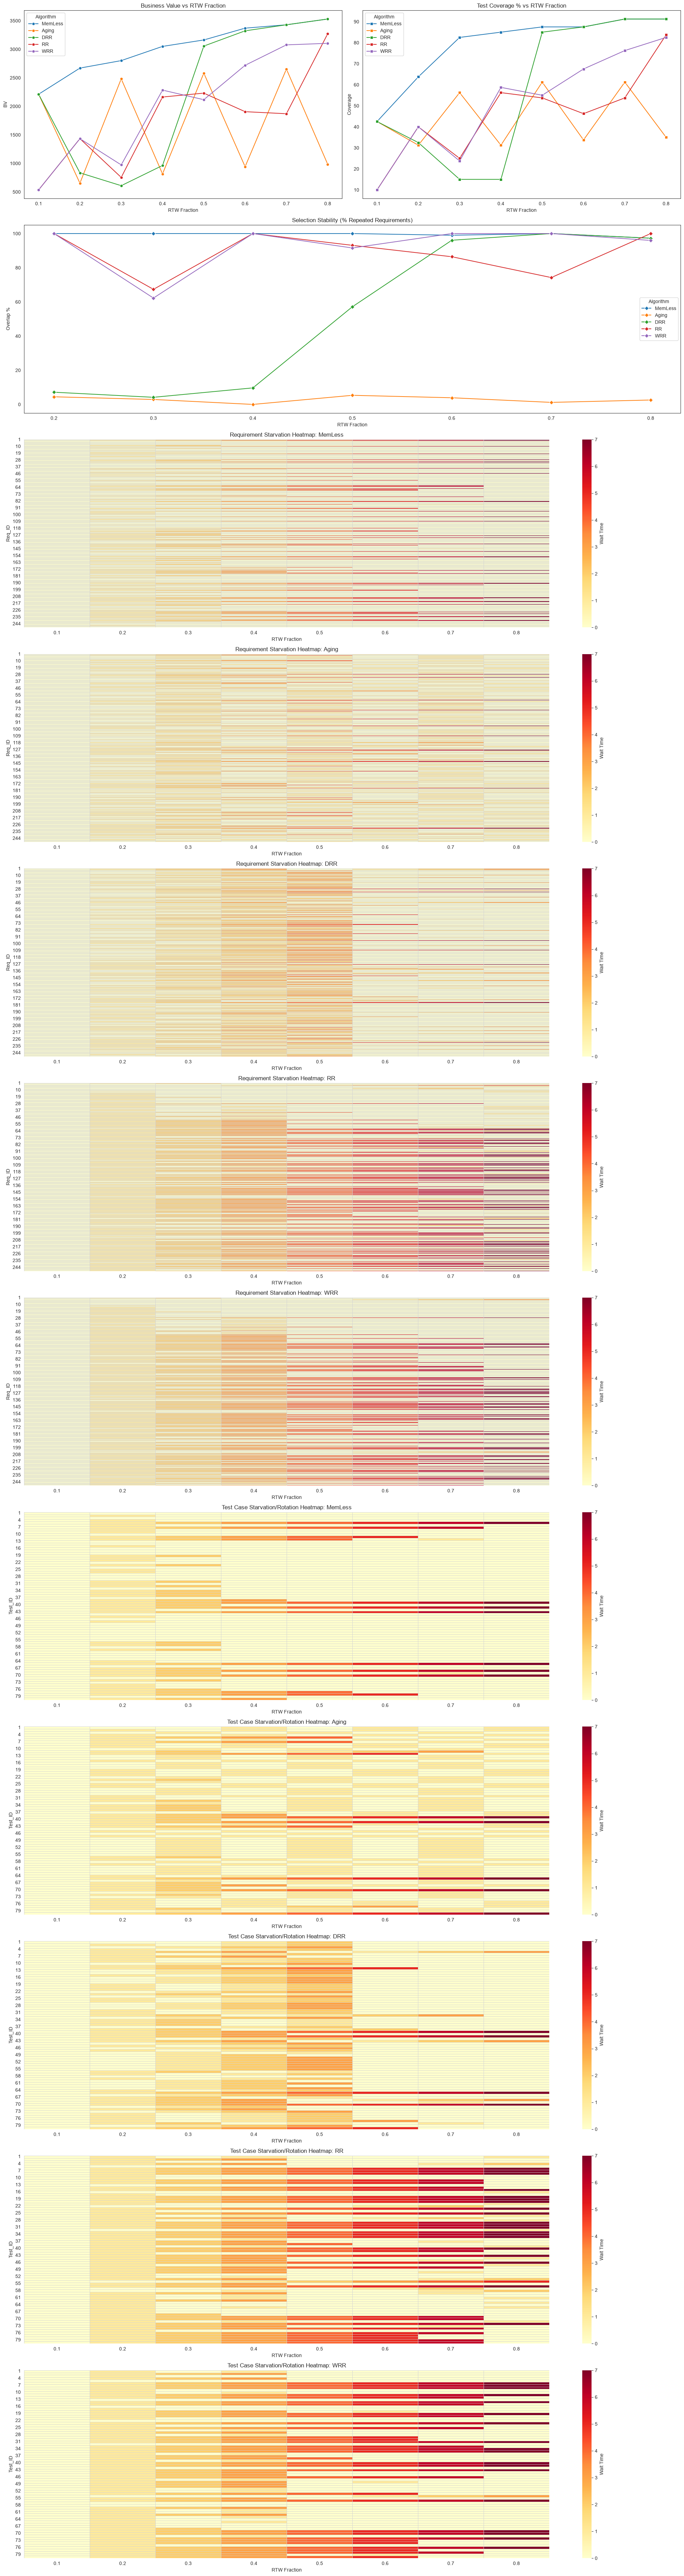

✅ Plot saved → /Users/aumgarasia/Desktop/SPE_2026/RESULTS/analysis.png


In [6]:
# ======================================================
# Cell 6: Visualizations
# ======================================================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("white")
plt.rcParams["figure.facecolor"] = "white"

# 12 rows: 2 summary + 5 req heatmaps + 5 test heatmaps
fig = plt.figure(figsize=(20, 75), facecolor="white")
gs  = fig.add_gridspec(12, 2)

ax1 = fig.add_subplot(gs[0, 0])
sns.lineplot(data=pd.DataFrame(perf), x="RTW Fraction", y="BV",
             hue="Algorithm", marker="o", ax=ax1)
ax1.set_title("Business Value vs RTW Fraction")

ax2 = fig.add_subplot(gs[0, 1])
sns.lineplot(data=pd.DataFrame(perf), x="RTW Fraction", y="Coverage",
             hue="Algorithm", marker="s", ax=ax2)
ax2.set_title("Test Coverage % vs RTW Fraction")

ax3 = fig.add_subplot(gs[1, :])
sns.lineplot(data=pd.DataFrame(stab), x="RTW Fraction", y="Overlap_Pct",
             hue="Algorithm", marker="D", ax=ax3)
ax3.set_title("Selection Stability (% Repeated Requirements)")
ax3.set_ylabel("Overlap %")

for i, a in enumerate(algos):
    ax = fig.add_subplot(gs[i+2, :])
    pivot = pd.DataFrame(hm_r[a]).pivot(index="Req_ID", columns="RTW Fraction", values="Wait")
    sns.heatmap(pivot, cmap="YlOrRd", ax=ax, linewidths=.5,
                linecolor="lightgrey", cbar_kws={"label": "Wait Time"})
    ax.set_title(f"Requirement Starvation Heatmap: {a}")

for i, a in enumerate(algos):
    ax = fig.add_subplot(gs[i+7, :])
    pivot = pd.DataFrame(hm_t[a]).pivot(index="Test_ID", columns="RTW Fraction", values="Wait")
    sns.heatmap(pivot, cmap="YlOrRd", ax=ax, linewidths=.5,
                linecolor="lightgrey", cbar_kws={"label": "Wait Time"})
    ax.set_title(f"Test Case Starvation/Rotation Heatmap: {a}")

plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, "analysis.png")
plt.savefig(plot_path, facecolor="white", dpi=150)
plt.show()
print(f"✅ Plot saved → {plot_path}")


In [7]:
# ======================================================
# Cell 7: Save Excel Report
# ======================================================
from openpyxl import Workbook
from openpyxl.drawing.image import Image as OpenpyxlImage

report_path = os.path.join(RESULTS_DIR, "Algorithm_Repetition_Report.xlsx")

with pd.ExcelWriter(report_path, engine="openpyxl") as writer:
    pd.DataFrame(perf).to_excel(writer, sheet_name="Summary", index=False)

    # Embed the visualization
    ws_viz = writer.book.create_sheet(title="Visualizations")
    img = OpenpyxlImage(plot_path)
    img.anchor = "A1"
    ws_viz.add_image(img)

    for a in algos:
        pd.DataFrame(sel_mat_r[a]).pivot(
            index="Req_ID", columns="RTW Fraction", values="Selected"
        ).to_excel(writer, sheet_name=f"Sel_Req_{a}")

        pd.DataFrame(hm_r[a]).pivot(
            index="Req_ID", columns="RTW Fraction", values="Wait"
        ).to_excel(writer, sheet_name=f"Wait_Req_{a}")

        pd.DataFrame(sel_mat_t[a]).pivot(
            index="Test_ID", columns="RTW Fraction", values="Selected"
        ).to_excel(writer, sheet_name=f"Sel_Test_{a}")

        pd.DataFrame(hm_t[a]).pivot(
            index="Test_ID", columns="RTW Fraction", values="Wait"
        ).to_excel(writer, sheet_name=f"Wait_Test_{a}")

print(f"✅ Report saved → {report_path}")


✅ Report saved → /Users/aumgarasia/Desktop/SPE_2026/RESULTS/Algorithm_Repetition_Report.xlsx
